In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
iris = load_iris() # Tải dữ liệu Iris gồm 150 Mẫu hoa

X = iris.data # Lấy dữ liệu đặc trưng của hoa
y = iris.target # Lẫy nhãn của từng loại hoa

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4,random_state=42
    )

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
k_values = [1,3,5,6,9,15,21,35,50,90] # Giới hạn K tối đa bằng số lượng mẫu huấn luyện (90)
accuracy_values = []

for k in k_values:
    knn_model = KNeighborsClassifier(n_neighbors=k)

    knn_model.fit(X_train_scaled, y_train)

    y_pred = knn_model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)

    accuracy_values.append(accuracy)

    print(f"K = {k}: Accuracy = {accuracy:.2f}")

# Tìm K tối ưu
best_k = list(k_values)[np.argmax(accuracy_values)]

print("\nGiá trị K tối ưu:", best_k)
print("Độ chính xác cao nhất:", max(accuracy_values))

K = 1: Accuracy = 0.97
K = 3: Accuracy = 0.98
K = 5: Accuracy = 0.98
K = 6: Accuracy = 0.98
K = 9: Accuracy = 0.98
K = 15: Accuracy = 0.97
K = 21: Accuracy = 0.98
K = 35: Accuracy = 0.87
K = 50: Accuracy = 0.83
K = 90: Accuracy = 0.30

Giá trị K tối ưu: 3
Độ chính xác cao nhất: 0.9833333333333333


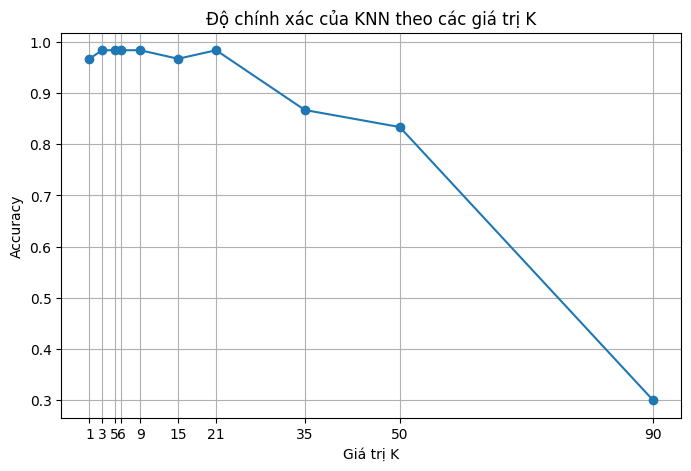

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, accuracy_values, marker='o')

plt.xlabel('Giá trị K')
plt.ylabel('Accuracy')
plt.title('Độ chính xác của KNN theo các giá trị K')
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [ ]:
distance_metrics = [
    ('Euclidean', 'euclidean', 2),
    ('Manhattan', 'manhattan', 1),
    ('Minkowski (p=3)', 'minkowski', 3)
]

results = []

for name, metric, p in distance_metrics:

    knn_model = KNeighborsClassifier(
        n_neighbors=best_k,
        metric=metric,
        p=p
    )

    knn_model.fit(X_train_scaled, y_train)

    y_pred = knn_model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        'Khoảng cách': name,
        'K': best_k,
        'Accuracy': accuracy
    })

    print(f"\nPhương pháp: {name}")
    print(f"Accuracy: {accuracy:.2f}")

    print("Ma trận nhầm lẫn:")
    print(confusion_matrix(y_test, y_pred))

    print("Báo cáo phân loại:")
    print(classification_report(
        y_test, y_pred,
        target_names=iris.target_names
    ))

results_df = pd.DataFrame(results)

print("\nBẢNG SO SÁNH CÁC PHƯƠNG PHÁP")
print(results_df)


Phương pháp: Euclidean
Accuracy: 0.98
Ma trận nhầm lẫn:
[[23  0  0]
 [ 0 19  0]
 [ 0  1 17]]
Báo cáo phân loại:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        23
  versicolor       0.95      1.00      0.97        19
   virginica       1.00      0.94      0.97        18

    accuracy                           0.98        60
   macro avg       0.98      0.98      0.98        60
weighted avg       0.98      0.98      0.98        60


Phương pháp: Manhattan
Accuracy: 0.98
Ma trận nhầm lẫn:
[[23  0  0]
 [ 0 19  0]
 [ 0  1 17]]
Báo cáo phân loại:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        23
  versicolor       0.95      1.00      0.97        19
   virginica       1.00      0.94      0.97        18

    accuracy                           0.98        60
   macro avg       0.98      0.98      0.98        60
weighted avg       0.98      0.98      0.98        60


Phương pháp

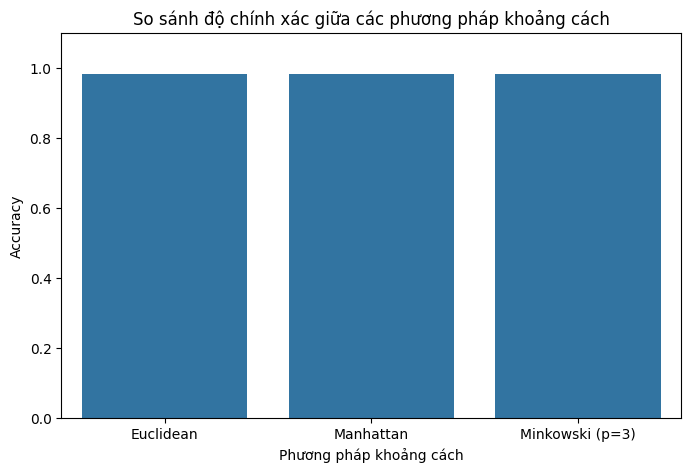

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x='Khoảng cách',
    y='Accuracy'
)

plt.title('So sánh độ chính xác giữa các phương pháp khoảng cách')
plt.xlabel('Phương pháp khoảng cách')
plt.ylabel('Accuracy')
plt.ylim(0, 1.1)

plt.show()

Phương pháp tốt nhất:
Khoảng cách    Euclidean
K                      3
Accuracy        0.983333
Name: 0, dtype: object


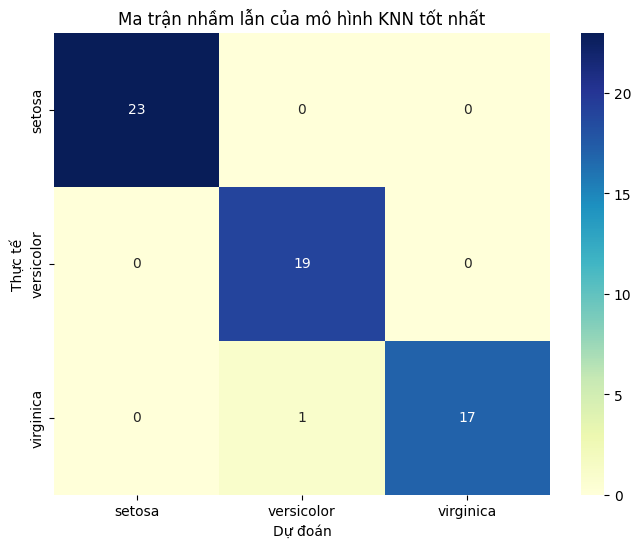

In [ ]:
best_metric = results_df.loc[
    results_df['Accuracy'].idxmax()
]

print("Phương pháp tốt nhất:")
print(best_metric)

knn_best = KNeighborsClassifier(
    n_neighbors=best_k,
    metric=distance_metrics[
        results_df['Accuracy'].idxmax()
    ][1],
    p=distance_metrics[
        results_df['Accuracy'].idxmax()
    ][2]
)

knn_best.fit(X_train_scaled, y_train)

y_pred_best = knn_best.predict(X_test_scaled)

conf_matrix = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(8, 6))

sns.heatmap(
    conf_matrix,
    annot=True,
    cmap="YlGnBu",
    fmt="d",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title('Ma trận nhầm lẫn của mô hình KNN tốt nhất')

plt.show()